# Лабораторная работа №4 «Интерполяция, аппроксимация, линейная регрессия»

Выбран вариант интерполяции. Сравним четыре библиотечных метода и собственную
линейную интерполяцию для $f(x) = \sin(x)$ на $[-\pi, \pi]$ с шагом $h = \pi/4$.

Ячейки выполняются сверху вниз. В последней ячейке вводите точки по одной;
пустая строка завершает ввод. Зависимости: NumPy, SciPy и Matplotlib.
Если их нет в ядре, установите командой `%pip install numpy scipy matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import interpolate

## Исходная функция и узлы

Задаём функцию в коде. Девять равномерных узлов включают оба конца отрезка.
Плотная сетка нужна только для графиков и оценки погрешности, а не для обучения методов.

In [2]:
def function(x):
    """Вычисляет исходную функцию sin(x)."""
    return np.sin(x)


left = -np.pi
right = np.pi
step = np.pi / 4
node_count = round((right - left) / step) + 1
x_nodes = np.linspace(left, right, node_count)
y_nodes = function(x_nodes)
x_grid = np.linspace(left, right, 1001)
y_exact = function(x_grid)

print(f"Отрезок: [{left:.6f}, {right:.6f}], шаг: {step:.6f}")
print(f"{'x':>12} | {'sin(x)':>12}")
for x, y in zip(x_nodes, y_nodes):
    print(f"{x:>12.6f} | {y:>12.6f}")

Отрезок: [-3.141593, 3.141593], шаг: 0.785398
           x |       sin(x)
   -3.141593 |    -0.000000
   -2.356194 |    -0.707107
   -1.570796 |    -1.000000
   -0.785398 |    -0.707107
    0.000000 |     0.000000
    0.785398 |     0.707107
    1.570796 |     1.000000
    2.356194 |     0.707107
    3.141593 |     0.000000


## Собственная линейная интерполяция

Для точки $x$ находим соседние узлы $x_i$, $x_{i+1}$ и вычисляем

$$L(x) = y_i + (y_{i+1} - y_i)\frac{x - x_i}{x_{i+1} - x_i}.$$

Границы включены. Значения за отрезком и нечисловые значения не допускаются.
Одна и та же функция обрабатывает отдельную точку и массив точек.

In [3]:
def validate_points(points, x_nodes):
    """Проверяет конечность точек и принадлежность отрезку узлов."""
    points = np.asarray(points, dtype=float)
    if not np.all(np.isfinite(points)):
        raise ValueError("Введите конечное число.")
    if np.any((points < x_nodes[0]) | (points > x_nodes[-1])):
        raise ValueError(
            f"Точка должна лежать в [{x_nodes[0]:.15g}, "
            f"{x_nodes[-1]:.15g}]."
        )
    return points


def linear_interpolation(points, x_nodes, y_nodes):
    """Интерполирует значения между соседними возрастающими узлами."""
    points = validate_points(points, x_nodes)
    indices = np.searchsorted(x_nodes, points, side="right") - 1
    indices = np.clip(indices, 0, len(x_nodes) - 2)
    fraction = (
        (points - x_nodes[indices])
        / (x_nodes[indices + 1] - x_nodes[indices])
    )
    return y_nodes[indices] + fraction * (
        y_nodes[indices + 1] - y_nodes[indices]
    )

## Библиотечные методы

Линейный, квадратичный и кубический интерполянты строим функцией
`make_interp_spline` со степенями 1, 2 и 3. Это кусочные полиномы,
а не один полином на всём отрезке.

Кубическая интерполяция тоже является сплайном. Чтобы четвёртый метод отличался,
для `CubicSpline` выбираем естественные граничные условия: вторая производная
на концах равна нулю. Кубический метод `make_interp_spline` использует условия
not-a-knot. Для синуса естественные условия согласуются со второй производной
исходной функции на концах выбранного отрезка.

Описание методов: [make_interp_spline](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.make_interp_spline.html),
[CubicSpline](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html).

In [4]:
methods = {
    "Линейная": interpolate.make_interp_spline(x_nodes, y_nodes, k=1),
    "Квадратичная": interpolate.make_interp_spline(x_nodes, y_nodes, k=2),
    "Кубическая (not-a-knot)": interpolate.make_interp_spline(
        x_nodes, y_nodes, k=3
    ),
    "Естественный кубический сплайн": interpolate.CubicSpline(
        x_nodes, y_nodes, bc_type="natural", extrapolate=False
    ),
    "Собственная линейная": lambda points: linear_interpolation(
        points, x_nodes, y_nodes
    ),
}
results = {name: method(x_grid) for name, method in methods.items()}

## Визуализация

Показываем каждый метод отдельно, чтобы совпадающие кривые не скрывали друг друга.
На каждом графике отмечены узлы, исходная функция и интерполянт.

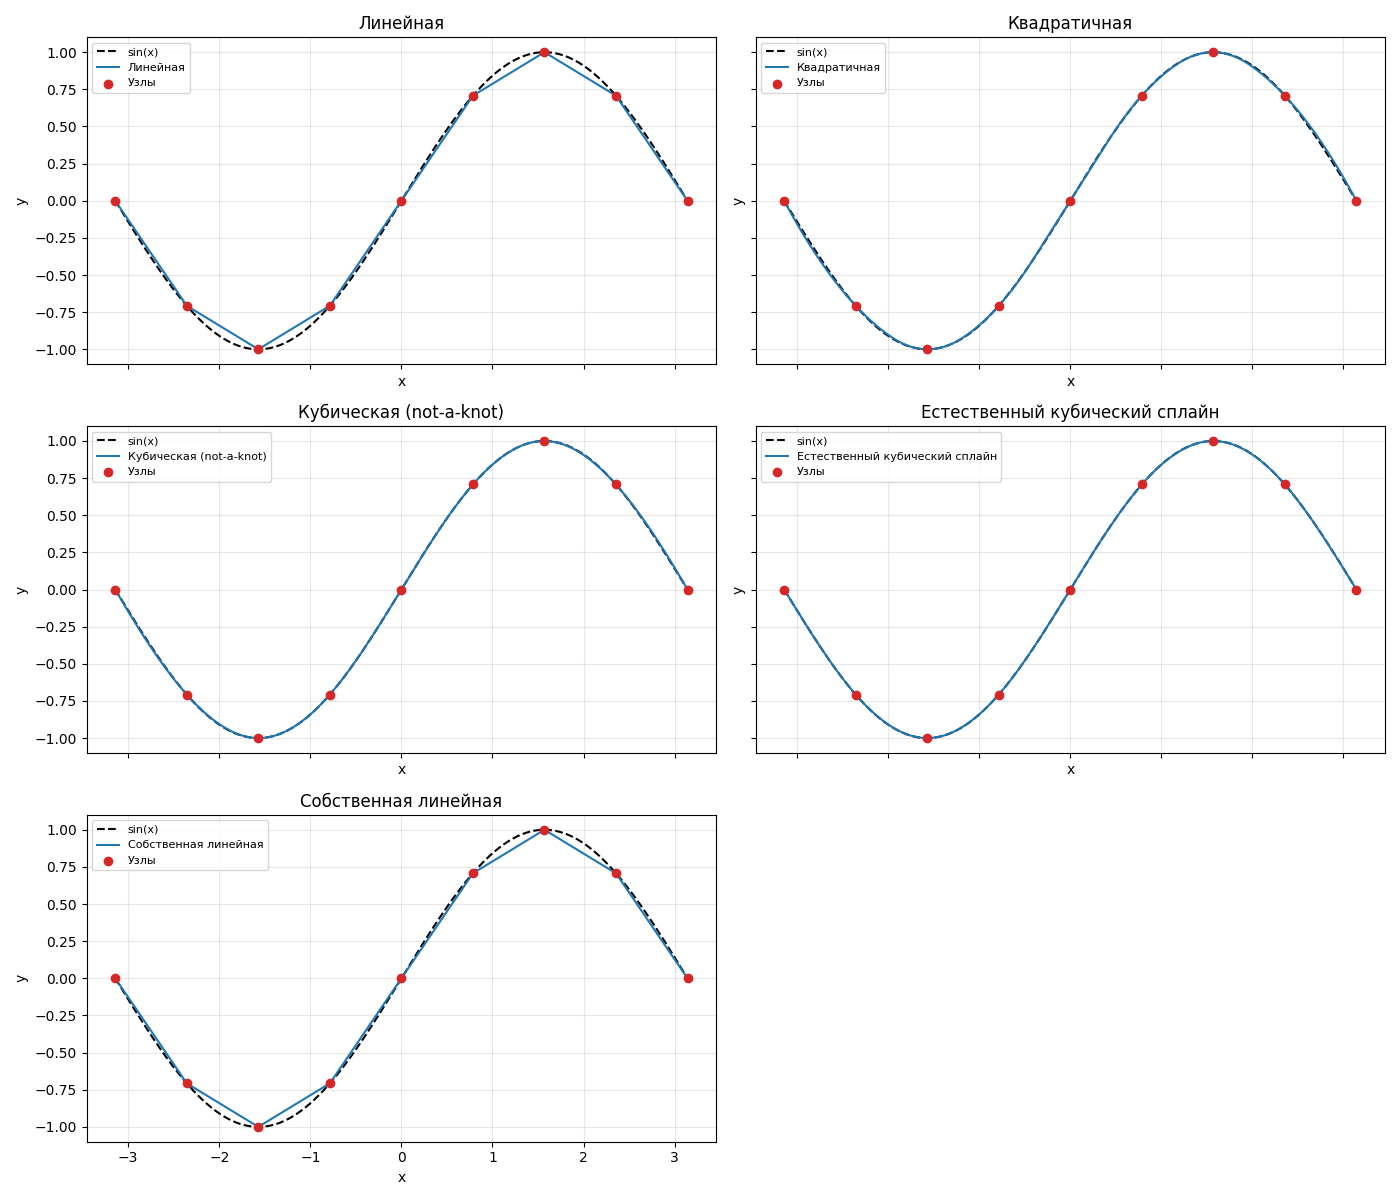

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True, sharey=True)
for ax, (name, values) in zip(axes.flat, results.items()):
    ax.plot(x_grid, y_exact, color="black", linestyle="--", label="sin(x)")
    ax.plot(x_grid, values, color="tab:blue", label=name)
    ax.scatter(x_nodes, y_nodes, color="tab:red", label="Узлы", zorder=3)
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

## Оценка погрешности

Для 1001 точки вычисляем максимальную абсолютную ошибку и среднеквадратичную
ошибку (RMSE). Максимум на сетке — численная оценка, а не доказанная верхняя
граница ошибки на всём непрерывном отрезке.

Метод                              |  Макс. ошибка |          RMSE
Линейная                           |  7.037704e-02 |  3.926472e-02
Квадратичная                       |  1.961181e-02 |  7.523300e-03
Кубическая (not-a-knot)            |  7.748695e-03 |  2.941614e-03
Естественный кубический сплайн     |  1.065975e-03 |  5.332134e-04
Собственная линейная               |  7.037704e-02 |  3.926472e-02


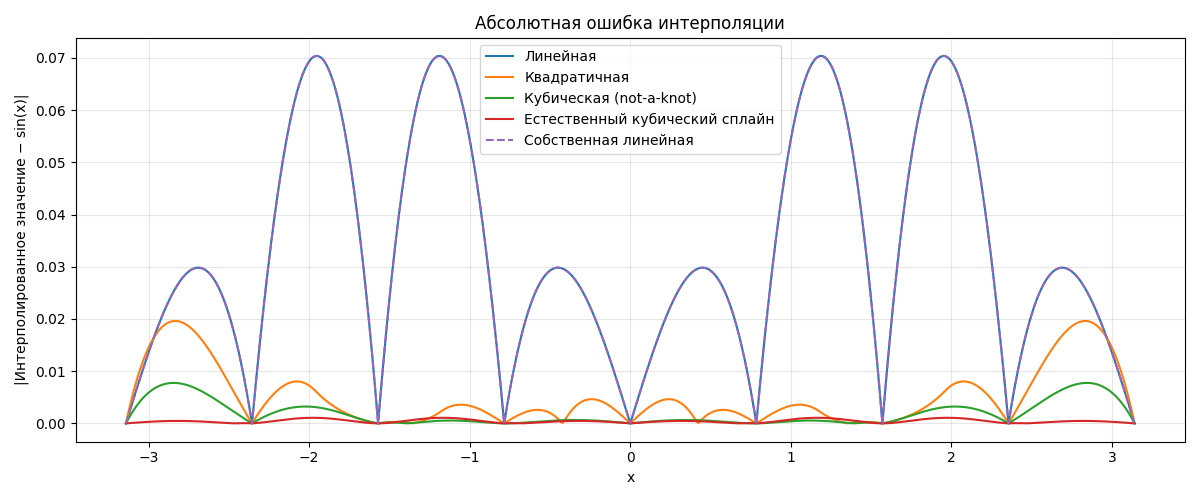

In [6]:
errors = {
    name: np.abs(values - y_exact) for name, values in results.items()
}
print(f"{'Метод':<34} | {'Макс. ошибка':>13} | {'RMSE':>13}")
for name, error in errors.items():
    rmse = np.sqrt(np.mean(error ** 2))
    print(f"{name:<34} | {np.max(error):>13.6e} | {rmse:>13.6e}")

plt.figure(figsize=(12, 5))
styles = ["-", "-", "-", "-", "--"]
for (name, error), style in zip(errors.items(), styles):
    plt.plot(x_grid, error, linestyle=style, label=name)
plt.title("Абсолютная ошибка интерполяции")
plt.xlabel("x")
plt.ylabel("|Интерполированное значение − sin(x)|")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Проверка в узлах и сравнение линейных реализаций

Интерполяция должна воспроизводить значения исходной функции в узлах.
Собственную реализацию дополнительно сравниваем с библиотечной на плотной сетке.

In [7]:
for name, method in methods.items():
    np.testing.assert_allclose(method(x_nodes), y_nodes, atol=1e-12, rtol=0)
np.testing.assert_allclose(
    results["Собственная линейная"], results["Линейная"],
    atol=1e-12, rtol=0,
)
print("Все методы проходят через узлы с точностью 1e-12.")
print("Собственная и библиотечная линейные реализации совпадают на сетке.")

Все методы проходят через узлы с точностью 1e-12.
Собственная и библиотечная линейные реализации совпадают на сетке.


## Выводы

На выбранной функции и сетке линейная интерполяция даёт наибольшую ошибку.
Квадратичная точнее, кубическая ещё точнее. Естественный кубический сплайн
имеет наименьшую максимальную ошибку среди рассмотренных методов для этой задачи;
его граничные условия подходят синусу на выбранном отрезке.

Собственная линейная интерполяция воспроизводит библиотечный результат с учётом
погрешности вычислений. В узлах все методы совпадают с исходной функцией,
поэтому для сравнения точности нужны также точки между узлами.

Линейный метод прост и непрерывен, но имеет изломы в узлах. Квадратичные
и кубические сплайны дают более гладкие кривые. Выбор степени и граничных
условий влияет на ошибку; результаты этого примера не означают, что один метод
будет лучшим для любой функции и любого шага.

## Ввод точки с клавиатуры

Введите число в радианах внутри $[-\pi, \pi]$, например `0.5`.
Допускается десятичная запятая. Выражения вроде `pi/2` не вычисляются:
для них нужно ввести численное значение. Вне отрезка программа сообщает об ошибке
и предлагает повторить ввод. Пустая строка завершает работу.

Для каждой точки выводятся точное значение, результат каждого метода и абсолютная
ошибка. Сохранённый пример выполнения использует точку `0.5`.

In [8]:
def predict_point(point):
    """Показывает интерполяцию и абсолютную ошибку для одной точки."""
    point = float(validate_points(point, x_nodes))
    exact = float(function(point))
    print(f"x = {point:.12g}; sin(x) = {exact:.12g}")
    print(f"{'Метод':<34} | {'Значение':>15} | {'Абс. ошибка':>13}")
    for name, method in methods.items():
        value = float(method(point))
        print(f"{name:<34} | {value:>15.10f} | {abs(value - exact):>13.6e}")


def run_interpolation():
    """Запрашивает точки до пустой строки или окончания ввода."""
    while True:
        try:
            text = input("Введите x (пустая строка — выход): ").strip()
        except EOFError:
            break
        if not text:
            break
        try:
            point = float(text.replace(",", "."))
        except ValueError:
            print("Введите число, например 0.5.")
            continue
        try:
            predict_point(point)
        except ValueError as error:
            print(error)


run_interpolation()

x = 0.5; sin(x) = 0.479425538604
Метод                              |        Значение |   Абс. ошибка
Линейная                           |    0.4501581581 |  2.926738e-02
Квадратичная                       |    0.4814220920 |  1.996553e-03
Кубическая (not-a-knot)            |    0.4789349379 |  4.906008e-04
Естественный кубический сплайн     |    0.4791234655 |  3.020731e-04
Собственная линейная               |    0.4501581581 |  2.926738e-02
